# Burgers equation: comparing optimizers

This notebook is one of three problems on which we compare **Adam**, **Muon** and **SOAP** (and, on Burgers and Darcy, **Muon-spec**) as optimizers for the **physics-informed neural operator (PINO)** (Li, Zheng et al., *Physics-Informed Neural Operator for Learning Partial Differential Equations*, arXiv:2111.03794).

The protocol follows the paper's Table 1:
- **Phase 1, operator learning.** Train a Fourier neural operator (FNO) with a data loss on a *coarse* grid plus a PDE-residual loss on a *finer* grid, then measure test error on several grids.
- **Phase 2, instance-wise fine-tuning.** Start from the Adam-trained operator and minimize the PDE loss on one test instance at a time (no data), tracking the error against a reference solution.

For each problem, all optimizers share the same initialization, data, batches and cosine learning-rate schedule. Learning rates are chosen on a validation set (never the test set).
- **Muon:** orthogonalizes updates of the hidden weight matrices; Adam handles the rest.
- **SOAP:** runs Adam in Shampoo's eigenbasis for every tensor.
- **Muon-spec** (`muon_spectral`): Muon that also orthogonalizes each Fourier mode's complex weight matrix, so it covers the spectral weights (99.6% of the parameters) that plain Muon leaves to Adam.

Both are implemented in `pino_bench.py`.

**Scale.** These are CPU runs (2 cores) with a half-width FNO (32 channels; the paper uses 64) and fewer iterations than the paper. Absolute errors are therefore above the paper's; the point is the **like-for-like comparison** of the optimizers.

This notebook only *reads* the saved results in `../results/burgers` (set `RUN_EXPERIMENT = True` to regenerate them).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))          # repo root: pino_bench.py, experiments.py, analysis.py
import pandas as pd, matplotlib.pyplot as plt
import analysis as an, experiments as ex
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 60)
PDE = "burgers"


## Problem

Viscous Burgers on the periodic interval, $u_t + (u^2/2)_x = \nu u_{xx}$ with $\nu = 0.01$, $x \in [0, 1)$, $t \in [0, 1]$.

- **Initial data:** $u_0 \sim \mathcal N\big(0,\ 625(-\Delta + 25 I)^{-2}\big)$; the operator maps $u_0 \mapsto u$ on $[0,1]^2$.
- **Reference solutions:** pseudo-spectral (1024 modes, 2/3 dealiasing) with integrating-factor RK4 and $\Delta t = 2\cdot10^{-4}$, stored on a 128 × 101 space-time grid. They agree with a 2048-mode, half-step run to $2\cdot10^{-6}$.
- **Grids:** data loss on **32 × 26** (space × time), PDE loss on **128 × 101**; test on 32 × 26, 64 × 51 and 128 × 101.
- **PDE loss:** Fourier derivatives in $x$, central differences in $t$, plus an initial-condition term.
- **Splits:** 800 training, 100 validation and 200 test instances.
- **Model and training:** FNO with width 32 and 12 × 12 modes, 6000 iterations, batch 8 + 8, 2 seeds.

### Configuration
This is the exact configuration used for the saved results (`experiments.cfg_for`).

In [2]:
cfg = ex.cfg_for(PDE)
{k: cfg[k] for k in cfg if k not in ("gen",)}

{'nu': 0.01,
 'n_train': 800,
 'n_val': 100,
 'n_test': 200,
 'model': {'modes': (12, 12),
  'width': 32,
  'layers': 4,
  'pad_frac': 0.25,
  'pad_mode': 'points'},
 'train': {'iters': 6000,
  'bs_data': 8,
  'bs_pde': 8,
  'data_res': (32, 26),
  'pde_res': (128, 101),
  'weights': {'data': 1.0, 'f': 1.0, 'ic': 1.0}},
 'test_res': [(32, 26), (64, 51), (128, 101)],
 'val_res': (128, 101),
 'finetune': {'iters': 1000,
  'n_instances': 5,
  'anchor': 0.0,
  'n_sweep_instances': 3,
  'sweep_frac': 0.5},
 'seeds': [0, 1],
 'sweep': 0.2}

### Reproducing

In [3]:
# Re-running the experiment from scratch takes about 13 hours on 2 CPU cores (resumable; see experiments.py).
# Results are written to ../runs/results; point the analysis cells at it with RESULTS = "../runs/results".
RUN_EXPERIMENT = False
RESULTS = an.RESULTS          # the saved results shipped with the repo
if RUN_EXPERIMENT:
    ex.run(PDE)
    RESULTS = os.path.join(ex.ROOT, "results")

## Learning-rate sweep
Short runs (20% of the full length, seed 0) on the base rates × {1/3, 1, 3}. Whenever the best rate fell on the top edge of the grid, the grid was extended upward (×3) until it didn't. The rate with the lowest **validation** error is used for the full runs.

In [4]:
an.sweep_table(PDE, RESULTS)

,optimizer,lr,iterations,val_error_pct,chosen
0,Adam,0.000333,1200,4.696,
1,Adam,0.001000,1200,2.391,
2,Adam,0.003000,1200,1.741,
3,Adam,0.009000,1200,1.381,<- best
4,Adam,0.027000,1200,2.090,
5,Muon,0.000333,1200,4.821,
6,Muon,0.001000,1200,2.012,
7,Muon,0.003000,1200,1.317,
8,Muon,0.009000,1200,1.285,<- best
9,Muon,0.027000,1200,2.292,


## Phase 1: operator learning
Final test error (%), mean ± std over seeds, for each test grid.

In [5]:
an.results_table(PDE, RESULTS)

,lr,seeds,"test (32, 26)","test (64, 51)","test (128, 101)",time / run (min)
optimizer,,,,,,
Adam,0.009,2,0.75 ± 0.01,1.77 ± 0.06,0.79 ± 0.01,80.1
Muon,0.009,2,0.59 ± 0.00,1.70 ± 0.01,0.66 ± 0.04,79.1
SOAP,0.009,2,0.56 ± 0.01,1.57 ± 0.03,0.53 ± 0.01,83.8
Muon-spec,0.009,2,0.54 ± 0.00,1.68 ± 0.01,0.49 ± 0.00,91.7


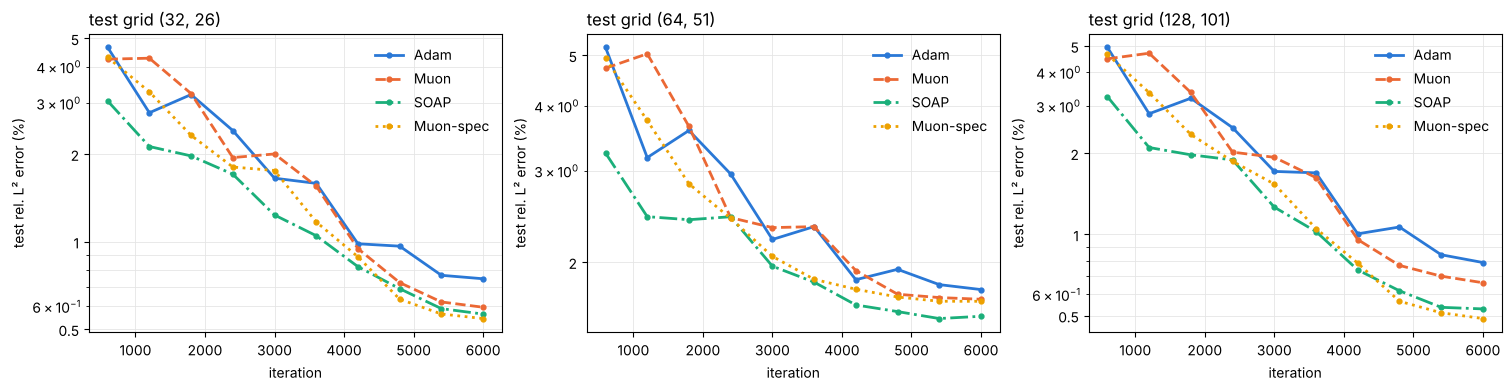

In [6]:
fig = an.plot_phase1(PDE, RESULTS, x='it'); plt.show()

The same curves against wall time:

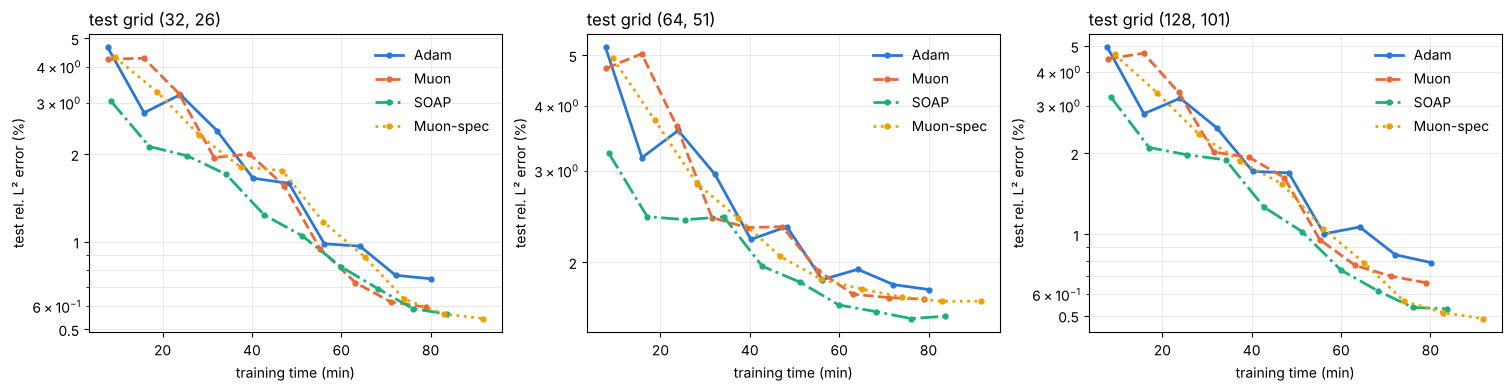

In [7]:
fig = an.plot_phase1(PDE, RESULTS, x='time'); plt.show()

## Phase 2: instance-wise fine-tuning
Each optimizer fine-tunes the **same** Adam-trained operator (seed 0) on each test instance, minimizing only the PDE loss, without the anchor term. The error is measured against the reference solution on the PDE grid.

In [8]:
an.ft_table(PDE, RESULTS)

,lr,instances,steps,start (%),final (%),final per instance (%),time / instance (s)
optimizer,,,,,,,
Adam,0.009,5,1000,0.85,0.267,"[0.529, 0.223, 0.211, 0.131, 0.24]",80
Muon,0.009,5,1000,0.85,0.237,"[0.47, 0.236, 0.256, 0.086, 0.135]",80
SOAP,0.009,5,1000,0.85,0.193,"[0.408, 0.185, 0.192, 0.077, 0.1]",114
Muon-spec,0.009,5,1000,0.85,0.199,"[0.327, 0.162, 0.283, 0.098, 0.128]",286


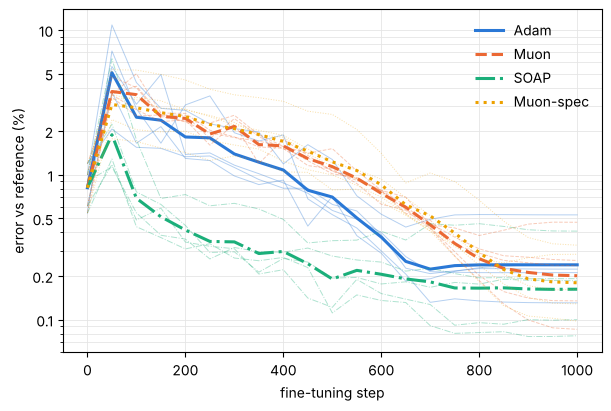

In [9]:
fig = an.plot_phase2(PDE, RESULTS, x='it'); plt.show()

## Observations

- **Phase 1: SOAP is best on every grid.** On the PDE grid it reaches 0.53% against Adam's 0.79%, about 33% lower. Muon sits in between: about 20% better than Adam on the data grid and 15% on the PDE grid. The two seeds agree to within ~0.05 points, so these gaps are well above seed noise.
- **Cost:** all three runs take about the same wall time, with SOAP about 5–10% slower per step.
- **The 51-time-point grid is worse for all three optimizers** (≈1.6–1.8% against ≈0.5–0.8%). It is the only test grid not used in training, and the time axis is non-periodic and zero-padded. Notebook 04 shows this is a discretization dependence of the FNO along the padded axis, not an optimizer effect.
- **Phase 2:** the same ordering. From 0.85%, after 1000 steps: Adam 0.27%, Muon 0.24%, SOAP 0.19%. SOAP's steps cost about 40% more, but it still ends lowest.
- **Muon-spec ties SOAP** (0.55 / 1.69 / 0.49%, at the same learning rate 9e-3 as the others), and fine-tunes to 0.20%. Orthogonalizing the spectral weights helps here.
- **Paper's PINO with Adam (width 64, longer training):** 0.17 / 0.28 / 0.38% on the three grids.